In [56]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from kagglehub import KaggleDatasetAdapter
import kagglehub
import ast
import numpy as np

In [57]:
# Find the project from either the notebook folder or the project root.
ROOT = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / 'data' / 'processed' / 'jev' / 'jev_full_v1.csv').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from within the coffee-project folder.')

CSV_PATH = ROOT / 'data' / 'processed' / 'jev' / 'jev_full_v1.csv'
df = pd.read_csv(CSV_PATH, dtype={'review_id': 'string', 'business_id': 'string'})
print(f'Loaded {len(df):,} reviews and {len(df.columns)} columns.')
df.head()

Loaded 22,703 reviews and 9 columns.


,review_id,business_id,text,good_wifi,easy_parking,quiet_atmosphere,enough_seating,outlets_available,work_friendly
0,L0jv8c2FbpWSlfNC6bbUEA,IDtLPgUrqorrpqSLdfMhZQ,What a great addition to the Funk Zone! Grab ...,0,0,0,0,0,0
1,Gczff1Qxg4WVmlBLPrZwzQ,34Eqv8jXgxg_EEwcsNgeeg,We absolutely love everything we have tried he...,0,0,0,0,0,0
2,bi6GaeWDGceGv62lXTIKQA,bjhCtlYHrkgA5Ku8l-rB3g,Very disappointed. We went to eat at 2:15 on ...,0,0,0,0,0,0
3,H4mSxGeKTv4VFcc9YUmtpQ,-kY_HDP7IMvGl-kBIZVU4A,The espresso here is excellent. My favorite pl...,1,0,1,0,-1,0
4,LFpaQzYkP5Pzm5lEjJpTRw,IDtLPgUrqorrpqSLdfMhZQ,Possibly the best breakfast sandwich EVER. On...,0,0,0,0,0,0


In [58]:
qualifiers = [
    'good_wifi',
    'easy_parking',
    'quiet_atmosphere',
    'enough_seating',
    'outlets_available',
    'work_friendly',
]

df['final_wfh_score'] = df[qualifiers].sum(axis=1, min_count=6)

df.head(10)

,review_id,business_id,text,good_wifi,easy_parking,quiet_atmosphere,enough_seating,outlets_available,work_friendly,final_wfh_score
0,L0jv8c2FbpWSlfNC6bbUEA,IDtLPgUrqorrpqSLdfMhZQ,What a great addition to the Funk Zone! Grab ...,0,0,0,0,0,0,0
1,Gczff1Qxg4WVmlBLPrZwzQ,34Eqv8jXgxg_EEwcsNgeeg,We absolutely love everything we have tried he...,0,0,0,0,0,0,0
2,bi6GaeWDGceGv62lXTIKQA,bjhCtlYHrkgA5Ku8l-rB3g,Very disappointed. We went to eat at 2:15 on ...,0,0,0,0,0,0,0
3,H4mSxGeKTv4VFcc9YUmtpQ,-kY_HDP7IMvGl-kBIZVU4A,The espresso here is excellent. My favorite pl...,1,0,1,0,-1,0,1
4,LFpaQzYkP5Pzm5lEjJpTRw,IDtLPgUrqorrpqSLdfMhZQ,Possibly the best breakfast sandwich EVER. On...,0,0,0,0,0,0,0
5,s_X5uNLjLSgK_itDNFiadg,MbzgGsMQpGyVrUJXi_Jw0Q,I am from Colorado and am visiting Santa Barba...,0,0,0,0,0,0,0
6,Q3fPo_x6xKxafAzy1hFITg,IDtLPgUrqorrpqSLdfMhZQ,Pricey ( a ham and cheese croissant was $5.50)...,0,0,0,0,0,0,0
7,NoPOfj7gC1l48dC0XH7Spw,KiE0h68HGOO7ZXAqkMBdiw,"I went in when they had 4 people working, wait...",0,0,0,0,0,0,0
8,u6EW2edED7ZfbZAw7lcYYQ,bjhCtlYHrkgA5Ku8l-rB3g,Great breads especially the German rye. My fa...,0,0,0,0,0,0,0
9,J8KTnbCtArCsPKynC4TwyA,34Eqv8jXgxg_EEwcsNgeeg,"Bomb. I go for the island bowl, always. \n\n""...",0,0,0,0,0,0,0


In [59]:
clean_data = (
    df.groupby('business_id', as_index=False)
    .agg(
        total_reviews=('review_id', 'nunique'),
        total_wfh_score=('final_wfh_score', 'sum'),
    )
)

clean_data.head()

,business_id,total_reviews,total_wfh_score
0,-kY_HDP7IMvGl-kBIZVU4A,330,33
1,-loV4cB2Uh9TCltTRgGzWQ,386,-17
2,0Qs-G8Xs-mz-jmQH5lez5A,23,2
3,0RxU5OglQyPVtLKC1LPgsA,511,-21
4,0iHHsSqphxrBWWecYEJcuQ,72,35


In [60]:
clean_data['average_wfh_score'] = (
    clean_data['total_wfh_score'] / clean_data['total_reviews']
)

clean_data.head()

,business_id,total_reviews,total_wfh_score,average_wfh_score
0,-kY_HDP7IMvGl-kBIZVU4A,330,33,0.100000
1,-loV4cB2Uh9TCltTRgGzWQ,386,-17,-0.044041
2,0Qs-G8Xs-mz-jmQH5lez5A,23,2,0.086957
3,0RxU5OglQyPVtLKC1LPgsA,511,-21,-0.041096
4,0iHHsSqphxrBWWecYEJcuQ,72,35,0.486111


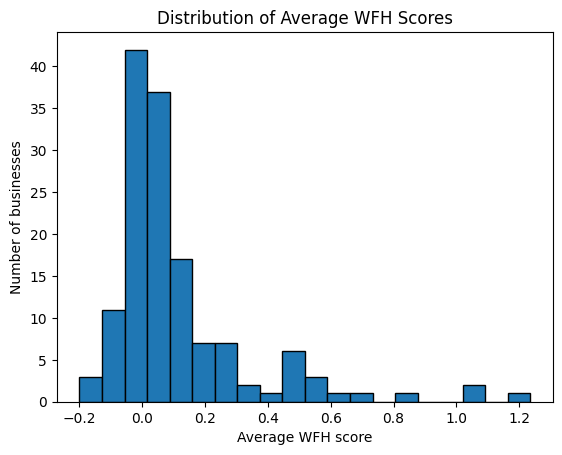

In [61]:
clean_data['average_wfh_score'].plot.hist(bins=20, edgecolor='black')

plt.xlabel('Average WFH score')
plt.ylabel('Number of businesses')
plt.title('Distribution of Average WFH Scores')
plt.show()

In [62]:
clean_data.shape

(142, 4)

In [63]:
score_counts = pd.DataFrame({
    'Score group': ['0 or less', 'Greater than 0'],
    'Number of businesses': [
        (clean_data['average_wfh_score'] <= 0).sum(),
        (clean_data['average_wfh_score'] > 0).sum(),
    ],
})

score_counts

,Score group,Number of businesses
0,0 or less,52
1,Greater than 0,90


I want to add weighting to good_wifi since this is probably the biggest thing that you need to be able to do work. I also want to add more weight to work_friendly. If someone mentions this its probably worth taking into account. 

In [64]:
df_weighted = df.copy()

df_weighted[['good_wifi', 'work_friendly']] *= 2
df_weighted['final_wfh_score'] = df_weighted[qualifiers].sum(axis=1, min_count=6)
df_weighted.head()

,review_id,business_id,text,good_wifi,easy_parking,quiet_atmosphere,enough_seating,outlets_available,work_friendly,final_wfh_score
0,L0jv8c2FbpWSlfNC6bbUEA,IDtLPgUrqorrpqSLdfMhZQ,What a great addition to the Funk Zone! Grab ...,0,0,0,0,0,0,0
1,Gczff1Qxg4WVmlBLPrZwzQ,34Eqv8jXgxg_EEwcsNgeeg,We absolutely love everything we have tried he...,0,0,0,0,0,0,0
2,bi6GaeWDGceGv62lXTIKQA,bjhCtlYHrkgA5Ku8l-rB3g,Very disappointed. We went to eat at 2:15 on ...,0,0,0,0,0,0,0
3,H4mSxGeKTv4VFcc9YUmtpQ,-kY_HDP7IMvGl-kBIZVU4A,The espresso here is excellent. My favorite pl...,2,0,1,0,-1,0,2
4,LFpaQzYkP5Pzm5lEjJpTRw,IDtLPgUrqorrpqSLdfMhZQ,Possibly the best breakfast sandwich EVER. On...,0,0,0,0,0,0,0


In [65]:
clean_data_2 = (
    df_weighted.groupby('business_id', as_index=False)
    .agg(
        total_reviews=('review_id', 'nunique'),
        total_wfh_score=('final_wfh_score', 'sum'),
    )
)

clean_data_2.head()

,business_id,total_reviews,total_wfh_score
0,-kY_HDP7IMvGl-kBIZVU4A,330,53
1,-loV4cB2Uh9TCltTRgGzWQ,386,-17
2,0Qs-G8Xs-mz-jmQH5lez5A,23,3
3,0RxU5OglQyPVtLKC1LPgsA,511,-19
4,0iHHsSqphxrBWWecYEJcuQ,72,51


In [66]:
clean_data_2['average_wfh_score'] = (
    clean_data_2['total_wfh_score'] / clean_data_2['total_reviews']
)


Visual 1: 
This determined that in order for a business to be considered good to work from, it would have to have at least a 0.25 score. This was chosen because we clearly see that the right tail starts at 0.25. This was also manually validated with a couple of reviews. 

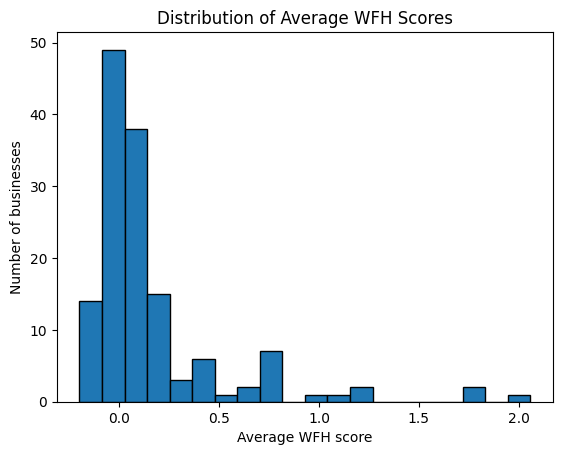

In [67]:
clean_data_2['average_wfh_score'].plot.hist(bins=20, edgecolor='black')

plt.xlabel('Average WFH score')
plt.ylabel('Number of businesses')
plt.title('Distribution of Average WFH Scores')
plt.show()

In [68]:
score_counts_2 = pd.DataFrame({
    'Score group': ['less than 0.25', 'Greater than or equal to 0.25'],
    'Number of businesses': [
        (clean_data_2['average_wfh_score'] < 0.25).sum(),
        (clean_data_2['average_wfh_score'] >= 0.25).sum(),
    ],
})

score_counts_2

,Score group,Number of businesses
0,less than 0.25,115
1,Greater than or equal to 0.25,27


Based off the graph above, there seems to be a tail after .25 score. I will look at these businessess to see if they are representative of good WFH

In [69]:
eligible_ids = clean_data_2.loc[
    clean_data_2['average_wfh_score'] >= 0.25,
    'business_id'
]

matching_reviews = df[df['business_id'].isin(eligible_ids)]

with pd.option_context('display.max_colwidth', None):
    display(
        matching_reviews[['business_id', 'text', 'final_wfh_score']]
        .sample(n=min(10, len(matching_reviews)), random_state=42)
    )

,business_id,text,final_wfh_score
6940,VgAKmXE8B7J0I_O_R13UKQ,Super smooth latte with perfect temperature and I was able taste the toasty bean flavor! Also the froth was thick ! Fantastic latte!!,0
10619,iJp9sq8UddLSrUtIieoD0A,"This place has gone downhill since it first opened. First of all - it's very dirty. There is dirt everywhere. The windows, the sills, the open pipes near the ceiling, the crumbs embedded in the old tables. Unbussed items sit around for hours while the counter staff chat to each other. The water dispenser is empty, as was the half and half container. There is barely any gelato in the freezer - it's full of empty unfilled containers. It's a shell of a place and clearly not run with care. The coffee was lukewarm and not very strong. This place needs a strong dose of care invested in it. It's the worst of what a coffee shop turns into when owners and management stop caring. Though the staff was friendly and the music was decent, it's a poor excuse for a coffee shop.",0
5787,VgAKmXE8B7J0I_O_R13UKQ,"Don't be fooled. Kids aloof about serving mediocre coffee. Maybe the somewhat empty shop on Saturday am should have tipped me off. \nDon't get me wrong, the coffee's ok. But they sell the experience online as a specialty shop. \nI drink decaf because I react adversely to caffeine. I asked what kind of decaf they had today, and the guy said ""decaf coffee"". Ok. Not a bad answer, but nothing different. Again, not a bad answer, but nothing special. When I ordered a decaf americano I asked if i drank it here if I could get a refill from the decaf refill station, and I was told I couldn't because I wasn't ordering coffee. My other cafe choice nearby lets me do that, so that was disappointing. \nReally, Starbucks is same same. My other local specialty coffee shop is superior (I don't want to be tacky and name them).",0
6434,VgAKmXE8B7J0I_O_R13UKQ,Just stopped in for a visitZ. Bomb Kona pour over. Love local cool coffee shops like this!,0
5188,gsXBNWHWhHv_f9NcwpVajw,"Still one of my favorite spots to grab a coffee and post up for some work in Santa Barbara. Very spacious facility with nice clean restrooms and a couple parking options. The coffee is delicious and unlike a lot of coffee shops in the area, this one actually offers filling breakfast options - double check on social before visiting but this has been the case every time i've gone. Great spot near downtown! Will be back.",2
6668,VgAKmXE8B7J0I_O_R13UKQ,"Simply the best coffee. Homegrown, family run, beans roasted in-house & onsite. I love the place, and I recommend it to my friends who come to town for an original SB experience.",0
10055,iJp9sq8UddLSrUtIieoD0A,"Great place, coffee was good. friendly and welcoming feel. Def worth a stop in!",0
9845,iJp9sq8UddLSrUtIieoD0A,"One of the best coffee shops I have ever been to! They have artsy cards and gifts, amazingly flavorful coffee and tea drinks, gelato, and great paninis! I come here quite often to do homework and get my ice blended mocha, which is normally watery and not too flavorful at other coffee places, but here it is the great texture, taste, caffine ratio, and everything! Same as the Chai! You'll love it. They employees are pretty sweet, very clean, and very helpful! Overall wonderful hangout spot",1
7956,4sOLSCiwSdHhzcXC9Sd0xQ,Cute coffee/tea house with nice seating and located right on State st.\n\nOrdered a nice cup of tea at a decent price. Yum...,0
782,KiE0h68HGOO7ZXAqkMBdiw,I stopped at this location for about an hour while passing through Santa Barbara on a road trip. The service was super friendly and it seemed like the baristas knew many of the customers who came in. They were out of several food items but my coffee was good and made quickly. There was amble seating and the air conditioner was blasting. A standard Starbucks experience.,1


In [70]:
clean_data_2
clean_data_2['wfh_flag'] = (
    clean_data_2['average_wfh_score'] >= 0.25
).astype(int)

clean_data_2.head()

,business_id,total_reviews,total_wfh_score,average_wfh_score,wfh_flag
0,-kY_HDP7IMvGl-kBIZVU4A,330,53,0.160606,0
1,-loV4cB2Uh9TCltTRgGzWQ,386,-17,-0.044041,0
2,0Qs-G8Xs-mz-jmQH5lez5A,23,3,0.130435,0
3,0RxU5OglQyPVtLKC1LPgsA,511,-19,-0.037182,0
4,0iHHsSqphxrBWWecYEJcuQ,72,51,0.708333,1


In [71]:
clean_data_2.shape

(142, 5)

In [72]:
df_business_raw = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "yelp-dataset/yelp-dataset",
    "yelp_academic_dataset_business.json",
    pandas_kwargs={"lines": True},
)

In [73]:
clean_data_2 = clean_data_2.merge(
    df_business_raw,
    on='business_id',
    how='left',
    validate='many_to_one',
    suffixes=('', '_business'),
)

In [74]:
clean_data_2.shape

(142, 18)

In [75]:
attribute_keys = (
    pd.read_csv("../raw/attributes.csv")["attribute"]
    .dropna()
    .drop_duplicates()
    .tolist()
)

# Handle missing dictionaries without changing the original column.
safe_attributes = clean_data_2["attributes"].apply(
    lambda value: value if isinstance(value, dict) else {}
)

attributes_df = pd.DataFrame(
    safe_attributes.tolist(),
    index=clean_data_2.index,
).reindex(columns=attribute_keys)

for key in attribute_keys:
    clean_data_2[f"attribute_{key}"] = attributes_df[key]

In [76]:
clean_data_2.head()

,business_id,total_reviews,total_wfh_score,average_wfh_score,wfh_flag,name,address,city,state,postal_code,...,attribute_RestaurantsCounterService,attribute_RestaurantsDelivery,attribute_RestaurantsGoodForGroups,attribute_RestaurantsPriceRange2,attribute_RestaurantsReservations,attribute_RestaurantsTableService,attribute_RestaurantsTakeOut,attribute_Smoking,attribute_WheelchairAccessible,attribute_WiFi
0,-kY_HDP7IMvGl-kBIZVU4A,330,53,0.160606,0,Dune Coffee Roasters - Anacapa,528 Anacapa St,Santa Barbara,CA,93101,...,NaN,NaN,NaN,2,NaN,NaN,True,NaN,NaN,u'free'
1,-loV4cB2Uh9TCltTRgGzWQ,386,-17,-0.044041,0,Renaud's Patisserie & Bistro,"1324 State St, Ste N, Arlington Plaza",Santa Barbara,CA,93101,...,NaN,True,True,2,False,NaN,True,NaN,NaN,u'no'
2,0Qs-G8Xs-mz-jmQH5lez5A,23,3,0.130435,0,Museum Cafe,1130 State St,Santa Barbara,CA,93101,...,NaN,False,True,2,True,NaN,True,NaN,NaN,u'no'
3,0RxU5OglQyPVtLKC1LPgsA,511,-19,-0.037182,0,Bree'osh,"1150 Coast Village Rd, Ste E",Santa Barbara,CA,93108,...,NaN,True,False,2,False,False,True,NaN,False,u'free'
4,0iHHsSqphxrBWWecYEJcuQ,72,51,0.708333,1,Cajé Coffee - Arlington St,1316 State St,Santa Barbara,CA,93101,...,NaN,False,NaN,2,NaN,NaN,True,NaN,True,u'free'


In [77]:
category_names = (
    pd.read_csv("../processed/categories.csv")["category"])

allowed_categories = set(category_names)

# Split each business's categories and remove surrounding spaces.
business_categories = clean_data_2["categories"].fillna("").apply(
    lambda value: {
        category.strip()
        for category in value.split(",")
        if category.strip()
    }
)

# True when the business has that exact category.
for category in category_names:
    clean_data_2[f"category_{category}"] = business_categories.apply(
        lambda values: category in values
    )

# True when at least one category is outside the CSV list.
clean_data_2["category_other"] = business_categories.apply(
    lambda values: bool(values - allowed_categories)
)

categories_exclude = pd.read_csv("../processed/categories_exclude.csv")
excluded = set(categories_exclude["category"])

clean_data_2 = clean_data_2[
    ~clean_data_2["categories"].fillna("").apply(
        lambda value: any(
            category.strip() in excluded
            for category in value.split(",")
        )
    )
]

clean_data_2.head()

,business_id,total_reviews,total_wfh_score,average_wfh_score,wfh_flag,name,address,city,state,postal_code,...,attribute_WiFi,category_Coffeeshops,category_Coffee & Tea,category_Cafes,category_Internet Cafes,category_Shared Office Spaces,category_Libraries,category_Coffee Roasteries,category_Themed Cafes,category_other
0,-kY_HDP7IMvGl-kBIZVU4A,330,53,0.160606,0,Dune Coffee Roasters - Anacapa,528 Anacapa St,Santa Barbara,CA,93101,...,u'free',False,True,False,False,False,False,True,False,True
1,-loV4cB2Uh9TCltTRgGzWQ,386,-17,-0.044041,0,Renaud's Patisserie & Bistro,"1324 State St, Ste N, Arlington Plaza",Santa Barbara,CA,93101,...,u'no',False,True,False,False,False,False,False,False,True
2,0Qs-G8Xs-mz-jmQH5lez5A,23,3,0.130435,0,Museum Cafe,1130 State St,Santa Barbara,CA,93101,...,u'no',False,False,True,False,False,False,False,False,True
3,0RxU5OglQyPVtLKC1LPgsA,511,-19,-0.037182,0,Bree'osh,"1150 Coast Village Rd, Ste E",Santa Barbara,CA,93108,...,u'free',False,True,False,False,False,False,False,False,True
4,0iHHsSqphxrBWWecYEJcuQ,72,51,0.708333,1,Cajé Coffee - Arlington St,1316 State St,Santa Barbara,CA,93101,...,u'free',False,True,False,False,False,False,False,False,True


In [78]:
days = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday",
]

# Handle missing hours without changing the original column.
safe_hours = clean_data_2["hours"].apply(
    lambda value: value if isinstance(value, dict) else {}
)

for day in days:
    day_hours = safe_hours.apply(lambda hours: hours.get(day))

    split_hours = (
        day_hours.astype("string")
        .str.split("-", n=1, expand=True)
        .reindex(columns=[0, 1])
    )

    clean_data_2[f"{day}_start"] = split_hours[0]
    clean_data_2[f"{day}_end"] = split_hours[1]


clean_data_2.head()

,business_id,total_reviews,total_wfh_score,average_wfh_score,wfh_flag,name,address,city,state,postal_code,...,Wednesday_start,Wednesday_end,Thursday_start,Thursday_end,Friday_start,Friday_end,Saturday_start,Saturday_end,Sunday_start,Sunday_end
0,-kY_HDP7IMvGl-kBIZVU4A,330,53,0.160606,0,Dune Coffee Roasters - Anacapa,528 Anacapa St,Santa Barbara,CA,93101,...,6:0,17:0,6:0,17:0,6:0,17:0,6:0,17:0,7:0,17:0
1,-loV4cB2Uh9TCltTRgGzWQ,386,-17,-0.044041,0,Renaud's Patisserie & Bistro,"1324 State St, Ste N, Arlington Plaza",Santa Barbara,CA,93101,...,7:0,16:0,7:0,16:0,7:0,16:0,7:0,16:0,7:0,15:0
2,0Qs-G8Xs-mz-jmQH5lez5A,23,3,0.130435,0,Museum Cafe,1130 State St,Santa Barbara,CA,93101,...,<NA>,<NA>,17:0,19:0,11:0,15:0,11:0,16:0,11:0,16:0
3,0RxU5OglQyPVtLKC1LPgsA,511,-19,-0.037182,0,Bree'osh,"1150 Coast Village Rd, Ste E",Santa Barbara,CA,93108,...,7:0,14:0,7:0,14:0,7:0,12:0,7:0,14:0,7:0,14:0
4,0iHHsSqphxrBWWecYEJcuQ,72,51,0.708333,1,Cajé Coffee - Arlington St,1316 State St,Santa Barbara,CA,93101,...,7:0,13:0,7:0,13:0,7:0,13:0,7:0,16:0,7:0,16:0


In [79]:
end_columns = [
    'Monday_end', 'Tuesday_end', 'Wednesday_end',
    'Thursday_end', 'Sunday_end'
]
# removed 'Friday_end', 'Saturday_end',


end_hours = clean_data_2[end_columns].apply(
    lambda col: pd.to_numeric(
        col.astype('string').str.split(':').str[0],
        errors='coerce',
    )
)

clean_data_2['total_late_days'] = end_hours.ge(20).sum(axis=1)


In [80]:
clean_data_2.loc[clean_data_2['total_late_days'] >= 1]

,business_id,total_reviews,total_wfh_score,average_wfh_score,wfh_flag,name,address,city,state,postal_code,...,Wednesday_end,Thursday_start,Thursday_end,Friday_start,Friday_end,Saturday_start,Saturday_end,Sunday_start,Sunday_end,total_late_days
7,1wvYBjX6radqmb_k0Fv_Ug,7,1,0.142857,0,Palihouse Santa Barbara,915 Garden St,Santa Barbara,CA,93101,...,22:0,8:0,22:0,8:0,22:0,8:0,22:0,8:0,22:0,3
12,3RtMd3VZ21WL5auDr6Jp9A,28,27,0.964286,1,Cafe Zoma,918 State St,Santa Barbara,CA,93101,...,20:0,7:0,20:0,7:0,22:0,7:0,22:0,9:0,20:0,5
14,3lty2YUwjp61iUqNgKVEMw,185,9,0.048649,0,Marmalade Cafe,3825 State St,Santa Barbara,CA,93105,...,21:0,11:0,21:0,11:0,21:0,8:0,21:0,8:0,21:0,5
15,3n7VGTZQKyWycuhU_j0lqA,60,13,0.216667,0,Alchemy Wellness Spa,35 W Haley St,Santa Barbara,CA,93101,...,18:0,9:0,20:0,9:0,18:0,9:0,18:0,9:0,17:0,1
19,5GUA13zYgw4_8F6qUMU_LA,63,0,0.000000,0,Green Star Coffee,38 W Victoria St,Santa Barbara,CA,93101,...,20:0,7:30,20:0,7:30,20:0,8:0,20:0,8:0,20:0,5
22,6RBrYMiAf8jFJI4fDoQpcw,6,0,0.000000,0,De La Guerra Dining Commons,1501 Residential Services,Santa Barbara,CA,93106,...,0:30,21:0,0:30,17:0,20:0,17:0,20:0,17:0,20:0,1
23,6afesz8yZhjOgijkWl4jig,78,-11,-0.141026,0,The Coffee Bean & Tea Leaf,811 State St,Santa Barbara,CA,93101,...,21:0,6:30,21:0,6:30,21:0,7:30,22:0,7:30,21:0,5
24,7grEnJV48N6BxbEP3uxISA,21,1,0.047619,0,Mr B Restaurant & Cafe,"140 S Hope Ave, Ste A102",Santa Barbara,CA,93105,...,20:0,10:0,20:0,10:0,20:0,10:0,20:0,10:0,20:0,5
25,9_uigKs9GCwg9dFKkq_Kfg,74,5,0.067568,0,Starbucks,800 State St,Santa Barbara,CA,93101,...,20:0,6:0,20:0,6:0,20:0,6:0,20:0,6:0,20:0,5
26,Aj44kUBmEfJlUsGCvKJKtw,21,8,0.380952,1,Starbucks,208 West Carrillo St,Santa Barbara,CA,93101,...,20:0,6:0,20:0,6:0,20:0,6:0,20:0,6:0,20:0,4


In [81]:
clean_data_2['late_close_flag'] = (
    (clean_data_2['wfh_flag'] == 1) &
    (clean_data_2['total_late_days'] >= 1)
).astype(int)

clean_data_2['late_wfh_score'] = (
    clean_data_2['average_wfh_score'] + clean_data_2['total_late_days']
)

clean_data_2.head()

,business_id,total_reviews,total_wfh_score,average_wfh_score,wfh_flag,name,address,city,state,postal_code,...,Thursday_end,Friday_start,Friday_end,Saturday_start,Saturday_end,Sunday_start,Sunday_end,total_late_days,late_close_flag,late_wfh_score
0,-kY_HDP7IMvGl-kBIZVU4A,330,53,0.160606,0,Dune Coffee Roasters - Anacapa,528 Anacapa St,Santa Barbara,CA,93101,...,17:0,6:0,17:0,6:0,17:0,7:0,17:0,0,0,0.160606
1,-loV4cB2Uh9TCltTRgGzWQ,386,-17,-0.044041,0,Renaud's Patisserie & Bistro,"1324 State St, Ste N, Arlington Plaza",Santa Barbara,CA,93101,...,16:0,7:0,16:0,7:0,16:0,7:0,15:0,0,0,-0.044041
2,0Qs-G8Xs-mz-jmQH5lez5A,23,3,0.130435,0,Museum Cafe,1130 State St,Santa Barbara,CA,93101,...,19:0,11:0,15:0,11:0,16:0,11:0,16:0,0,0,0.130435
3,0RxU5OglQyPVtLKC1LPgsA,511,-19,-0.037182,0,Bree'osh,"1150 Coast Village Rd, Ste E",Santa Barbara,CA,93108,...,14:0,7:0,12:0,7:0,14:0,7:0,14:0,0,0,-0.037182
4,0iHHsSqphxrBWWecYEJcuQ,72,51,0.708333,1,Cajé Coffee - Arlington St,1316 State St,Santa Barbara,CA,93101,...,13:0,7:0,13:0,7:0,16:0,7:0,16:0,0,0,0.708333


In [82]:
final_table = clean_data_2.copy()

In [83]:
final_table = final_table.drop(columns=['Monday_end', 'Tuesday_end', 'Wednesday_end','Thursday_end', 'Friday_end','Saturday_end','Sunday_end','Monday_start', 
                                        'Tuesday_start', 'Wednesday_start','Thursday_start', 'Friday_start','Saturday_start','Sunday_start',
                                        'attribute_DietaryRestrictions','attribute_DogsAllowed','attribute_GoodForDancing','attribute_GoodForKids',
                                        'attribute_HairSpecializesIn','attribute_RestaurantsAttire','attribute_RestaurantsDelivery','attribute_WheelchairAccessible',
                                        'attribute_Smoking','category_Cafes','category_Internet Cafes','category_Shared Office Spaces','category_Libraries',
                                        'category_Coffee Roasteries','category_Themed Cafes','category_other','category_Coffeeshops','category_Coffee & Tea','categories',
                                        'hours','attributes','attribute_AcceptsInsurance','attribute_AgesAllowed','attribute_Alcohol','attribute_BYOB','attribute_BYOBCorkage',
                                        'attribute_BestNights','attribute_BikeParking','attribute_BusinessAcceptsBitcoin','attribute_BusinessAcceptsCreditCards',
                                        'attribute_ByAppointmentOnly','attribute_Caters','attribute_CoatCheck','attribute_Corkage','attribute_DriveThru','attribute_GoodForMeal',
                                        'attribute_HappyHour','attribute_HasTV','attribute_Music','attribute_OutdoorSeating','attribute_RestaurantsCounterService',
                                        'attribute_RestaurantsGoodForGroups','attribute_RestaurantsPriceRange2','attribute_RestaurantsReservations','attribute_RestaurantsTableService',
                                        'attribute_RestaurantsTakeOut','attribute_Open24Hours'])

In [84]:
final_table.head()

,business_id,total_reviews,total_wfh_score,average_wfh_score,wfh_flag,name,address,city,state,postal_code,...,stars,review_count,is_open,attribute_Ambience,attribute_BusinessParking,attribute_NoiseLevel,attribute_WiFi,total_late_days,late_close_flag,late_wfh_score
0,-kY_HDP7IMvGl-kBIZVU4A,330,53,0.160606,0,Dune Coffee Roasters - Anacapa,528 Anacapa St,Santa Barbara,CA,93101,...,4.0,320,1,NaN,"{'garage': False, 'street': False, 'validated'...",u'average',u'free',0,0,0.160606
1,-loV4cB2Uh9TCltTRgGzWQ,386,-17,-0.044041,0,Renaud's Patisserie & Bistro,"1324 State St, Ste N, Arlington Plaza",Santa Barbara,CA,93101,...,4.0,379,1,"{'touristy': False, 'hipster': False, 'romanti...","{'garage': False, 'street': False, 'validated'...",u'quiet',u'no',0,0,-0.044041
2,0Qs-G8Xs-mz-jmQH5lez5A,23,3,0.130435,0,Museum Cafe,1130 State St,Santa Barbara,CA,93101,...,4.5,22,0,"{'romantic': False, 'intimate': False, 'classy...","{'garage': True, 'street': True, 'validated': ...",u'average',u'no',0,0,0.130435
3,0RxU5OglQyPVtLKC1LPgsA,511,-19,-0.037182,0,Bree'osh,"1150 Coast Village Rd, Ste E",Santa Barbara,CA,93108,...,4.5,497,1,"{'touristy': False, 'hipster': False, 'romanti...","{'garage': False, 'street': True, 'validated':...",u'average',u'free',0,0,-0.037182
4,0iHHsSqphxrBWWecYEJcuQ,72,51,0.708333,1,Cajé Coffee - Arlington St,1316 State St,Santa Barbara,CA,93101,...,4.5,72,1,NaN,"{u'valet': False, u'garage': True, u'street': ...",u'average',u'free',0,0,0.708333


In [85]:
def parse_attributes(value):
    if isinstance(value, dict):
        return value
    if isinstance(value, str):
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, dict) else {}
    return {}

for column in ['attribute_Ambience', 'attribute_BusinessParking']:
    expanded = pd.DataFrame(
        final_table[column].apply(parse_attributes).tolist(),
        index=final_table.index,
    ).add_prefix(f'{column}_')

    final_table[expanded.columns] = expanded

In [86]:
final_table = final_table.drop(columns=['attribute_Ambience','attribute_BusinessParking'])

In [87]:
columns = final_table.filter(
    regex=r'^attribute_(Ambience|BusinessParking)_'
).columns

final_table[columns] = final_table[columns].apply(
    lambda col: col.map({True: 1, False: 0, 'True': 1, 'False': 0}).astype('Int64')
)

In [88]:
columns = [
    'is_open',
    'attribute_NoiseLevel',
    'attribute_WiFi',
]

for column in columns:
    print(f'{column}: {final_table[column].unique().tolist()}')

is_open: [1, 0]
attribute_NoiseLevel: ["u'average'", "u'quiet'", nan, "'average'", "'quiet'", "'loud'", "u'loud'"]
attribute_WiFi: ["u'free'", "u'no'", nan, "'free'", "u'paid'", "'no'"]


In [89]:
final_table['attribute_WiFi'] = (
    final_table['attribute_WiFi']
    .replace({
        "u'free'": 1,
        "'free'": 1,
        "u'no'": -1,
        "'no'": -1,
        "u'paid'": 0,
    })
    .fillna(0)
    .astype(int)
)

/var/folders/1y/mz2h8lvj4sn_p_w4hfwq7m6w0000gn/T/ipykernel_96175/422153914.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  final_table['attribute_WiFi']


In [90]:
final_table['attribute_NoiseLevel'] = (
    final_table['attribute_NoiseLevel']
    .replace({
        "'quiet'": 1,
        "u'quiet'": 1,
        "'average'": 0,
        "u'average'": 0,
        "'loud'": -1,
        "u'loud'": -1,
    })
    .fillna(0)
    .astype(int)
)

/var/folders/1y/mz2h8lvj4sn_p_w4hfwq7m6w0000gn/T/ipykernel_96175/3466564231.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  final_table['attribute_NoiseLevel']


In [91]:
score_columns = [
    'attribute_NoiseLevel',
    'attribute_WiFi',
    'attribute_Ambience_touristy',
    'attribute_Ambience_hipster',
    'attribute_Ambience_romantic',
    'attribute_Ambience_divey',
    'attribute_Ambience_intimate',
    'attribute_Ambience_trendy',
    'attribute_Ambience_upscale',
    'attribute_Ambience_classy',
    'attribute_Ambience_casual',
    'attribute_BusinessParking_garage',
    'attribute_BusinessParking_street',
    'attribute_BusinessParking_validated',
    'attribute_BusinessParking_lot',
    'attribute_BusinessParking_valet',
]

final_table['yelp_final_score'] = final_table[score_columns].sum(axis=1)

final_table = final_table.drop(columns=[
    'attribute_NoiseLevel',
    'attribute_WiFi',
    'attribute_Ambience_touristy',
    'attribute_Ambience_hipster',
    'attribute_Ambience_romantic',
    'attribute_Ambience_divey',
    'attribute_Ambience_intimate',
    'attribute_Ambience_trendy',
    'attribute_Ambience_upscale',
    'attribute_Ambience_classy',
    'attribute_Ambience_casual',
    'attribute_BusinessParking_garage',
    'attribute_BusinessParking_street',
    'attribute_BusinessParking_validated',
    'attribute_BusinessParking_lot',
    'attribute_BusinessParking_valet'])

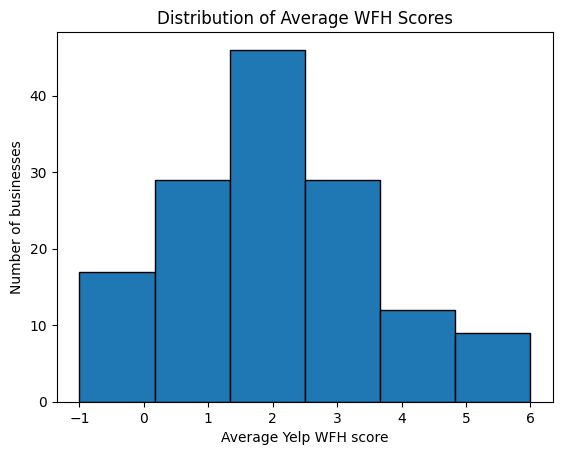

In [92]:
final_table['yelp_final_score'].plot.hist(bins=6, edgecolor='black')

plt.xlabel('Average Yelp WFH score')
plt.ylabel('Number of businesses')
plt.title('Distribution of Average WFH Scores')
plt.show()

In [93]:
columns = ['yelp_final_score', 'average_wfh_score']

for col in columns:
    minimum = final_table[col].min()
    maximum = final_table[col].max()
    final_table[f'{col}_normalized'] = (
        (final_table[col] - minimum) / (maximum - minimum)
        if maximum != minimum else 0
    )

Visual 2: 
This is an interesting visual because it shows that even if the business was market as good to WFH the reviews didn't always match that. In fact, yelp review scores are closer to 0 while yelp attribute score is closer to 0.5.

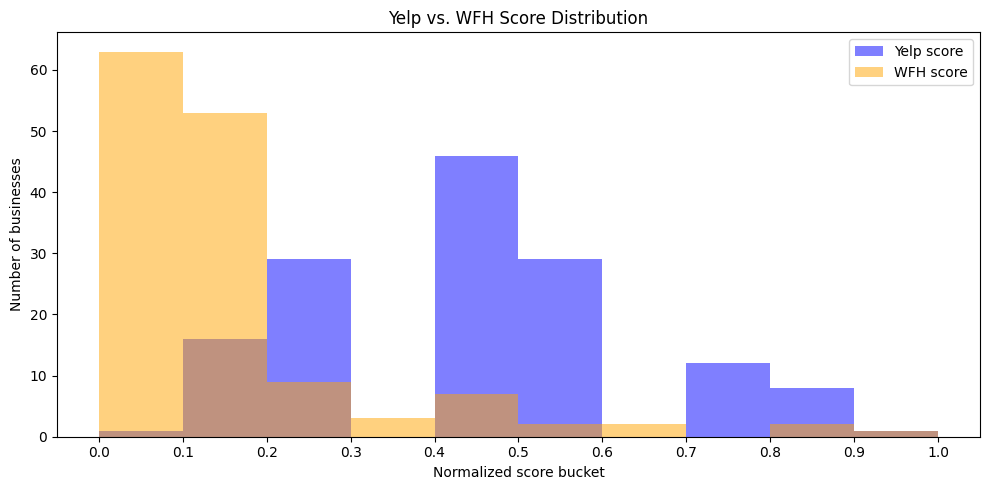

In [94]:
bins = np.linspace(0, 1, 11)  # Buckets: 0–0.1, 0.1–0.2, etc.

plt.figure(figsize=(10, 5))

plt.hist(
    final_table['yelp_final_score_normalized'].dropna(),
    bins=bins, alpha=0.5, color='blue', label='Yelp score',
)
plt.hist(
    final_table['average_wfh_score_normalized'].dropna(),
    bins=bins, alpha=0.5, color='orange', label='WFH score',
)

plt.xlabel('Normalized score bucket')
plt.ylabel('Number of businesses')
plt.title('Yelp vs. WFH Score Distribution')
plt.xticks(bins)
plt.legend()
plt.tight_layout()
plt.show()

In [95]:
final_table['combined_wfh_score'] = (
    0.60 * final_table['average_wfh_score_normalized']
    + 0.40 * final_table['yelp_final_score_normalized']
)

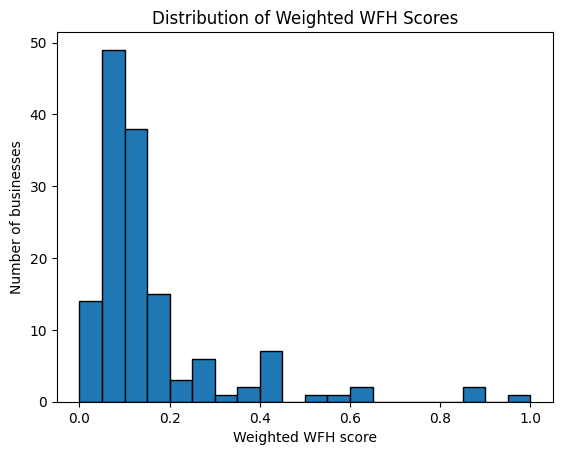

In [96]:
final_table['average_wfh_score_normalized'].plot.hist(bins=20, edgecolor='black')

plt.xlabel('Weighted WFH score')
plt.ylabel('Number of businesses')
plt.title('Distribution of Weighted WFH Scores')
plt.show()

Visual 3: Shows us that the threshold for what makes a business good to WFH or not could be changed according to the attributes given by yelp. Those business will be further inspected and reviews can be foudn: wfh_flag_0_score_above_0_3.xlsx. I dont think that we can really on attributes. For example one of the businessess has a coffee shop but is mostly a massage place, so even though it has a high score of 0.4535342262 the reviews are more reliable then yelp attributes. 

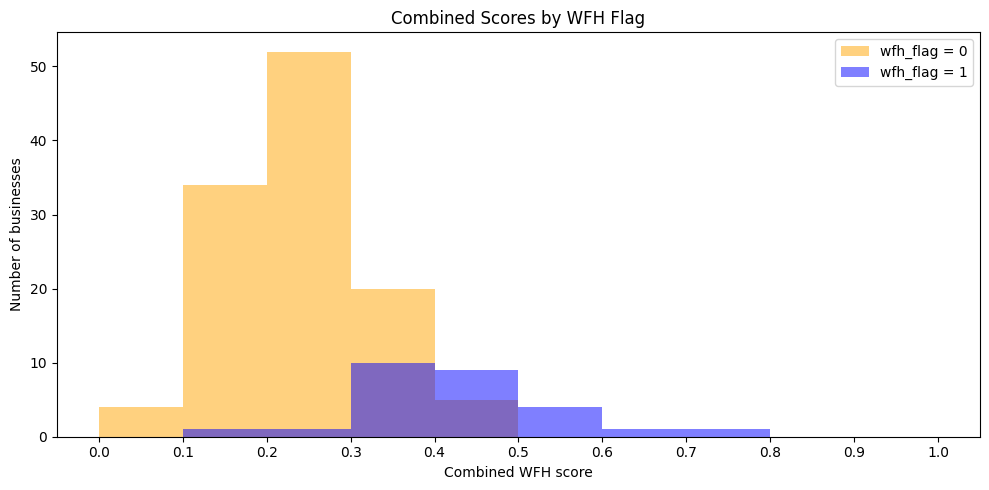

In [97]:
bins = np.linspace(0, 1, 11)

plt.figure(figsize=(10, 5))

for flag, color in [(0, 'orange'), (1, 'blue')]:
    scores = final_table.loc[
        final_table['wfh_flag'] == flag, 'combined_wfh_score'
    ].dropna()

    plt.hist(
        scores, bins=bins, alpha=0.5,
        color=color, label=f'wfh_flag = {flag}',
    )

plt.xlabel('Combined WFH score')
plt.ylabel('Number of businesses')
plt.title('Combined Scores by WFH Flag')
plt.xticks(bins)
plt.legend()
plt.tight_layout()
plt.show()

In [98]:

final_table['final_bucket'] = np.select(
    [
        (final_table['wfh_flag'] == 1) &
        (final_table['late_close_flag'] == 1),

        final_table['wfh_flag'] == 1,

        (final_table['wfh_flag'] == 0) &
        (final_table['stars'] >= 3),
    ],
    ['WFH Late', 'WFH', 'Other'],
    default='Uncategorized',
)

Visual 4: This shows the breakout of the kids of coffee shops that we have found. As anticipated, WFH coffee shops is a small subset and even smaller is the late open coffee shops. Those that fall under 'Uncategorized' are businesses such as McDonald's, Starbucks, and 7-Eleven

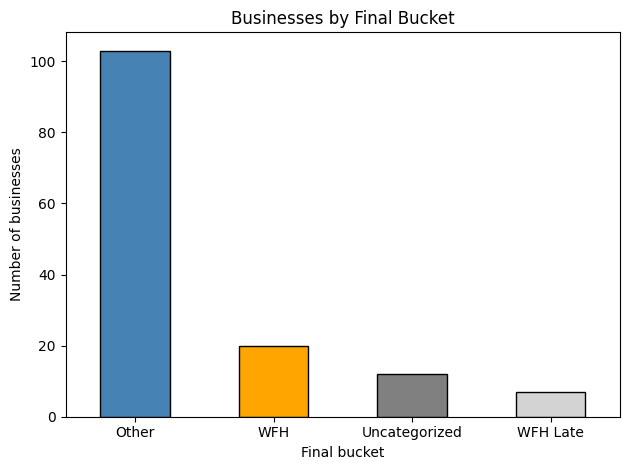

In [99]:

final_table['final_bucket'].value_counts().plot.bar(
    color=['steelblue', 'orange', 'gray', 'lightgray'],
    edgecolor='black',
)

plt.xlabel('Final bucket')
plt.ylabel('Number of businesses')
plt.title('Businesses by Final Bucket')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [100]:
final_table.loc[
    final_table['final_bucket'] == 'Uncategorized',
    ['name', 'wfh_flag', 'late_close_flag', 'stars', 'final_bucket'],
]

,name,wfh_flag,late_close_flag,stars,final_bucket
25,Starbucks,0,0,2.5,Uncategorized
27,7-Eleven,0,0,2.5,Uncategorized
73,Starbucks,0,0,2.0,Uncategorized
81,7-Eleven,0,0,2.5,Uncategorized
85,McDonald's,0,0,2.5,Uncategorized
104,Denny's,0,0,2.5,Uncategorized
107,McDonald's,0,0,2.5,Uncategorized
113,Cafe Shell,0,0,2.5,Uncategorized
118,7-Eleven,0,0,2.0,Uncategorized
121,Starbucks,0,0,2.5,Uncategorized


Visual 5: WFH Cafes seem to have the highest median in terms of yelp review stars which means people will also find top-rated coffee shops in this category. 

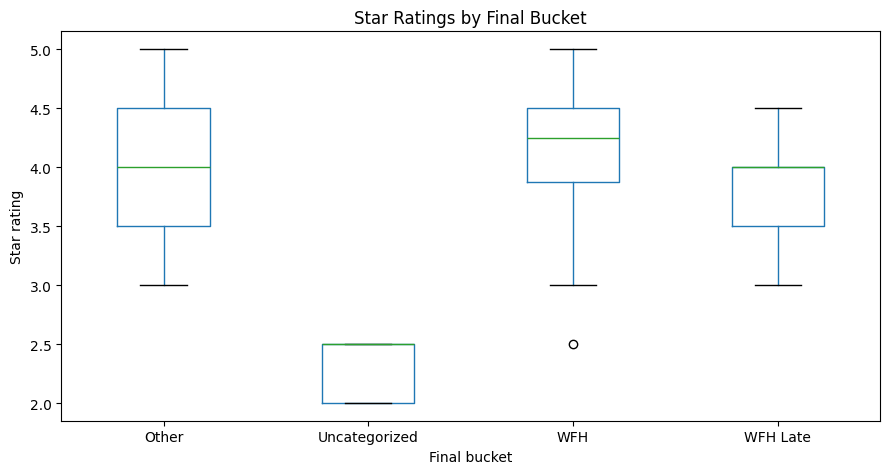

In [101]:
final_table.boxplot(
    column='stars',
    by='final_bucket',
    figsize=(9, 5),
    grid=False,
)

plt.xlabel('Final bucket')
plt.ylabel('Star rating')
plt.title('Star Ratings by Final Bucket')
plt.suptitle('')  # Remove the automatic subtitle
plt.tight_layout()
plt.show()

In [102]:
clean_data_3 = (
    df_weighted.groupby('business_id', as_index=False)
    .agg(
        total_reviews=('review_id', 'nunique'),
        **{
            f'total_{qualifier}': (qualifier, 'sum')
            for qualifier in qualifiers
        },
    )
)

clean_data_3['total_wfh_score'] = clean_data_3[
    [f'total_{qualifier}' for qualifier in qualifiers]
].sum(axis=1)

clean_data_3['average_wfh_score'] = (
    clean_data_3['total_wfh_score'] / clean_data_3['total_reviews']
)

clean_data_3.head()

,business_id,total_reviews,total_good_wifi,total_easy_parking,total_quiet_atmosphere,total_enough_seating,total_outlets_available,total_work_friendly,total_wfh_score,average_wfh_score
0,-kY_HDP7IMvGl-kBIZVU4A,330,18,18,6,14,-25,22,53,0.160606
1,-loV4cB2Uh9TCltTRgGzWQ,386,-2,16,7,-40,0,2,-17,-0.044041
2,0Qs-G8Xs-mz-jmQH5lez5A,23,0,0,2,-1,0,2,3,0.130435
3,0RxU5OglQyPVtLKC1LPgsA,511,2,10,3,-36,0,2,-19,-0.037182
4,0iHHsSqphxrBWWecYEJcuQ,72,-2,-1,10,9,1,34,51,0.708333


Visual 6: This is the distribution of the attributes in the whole data set. We see that mention of work-friendly plays the biggest role. 

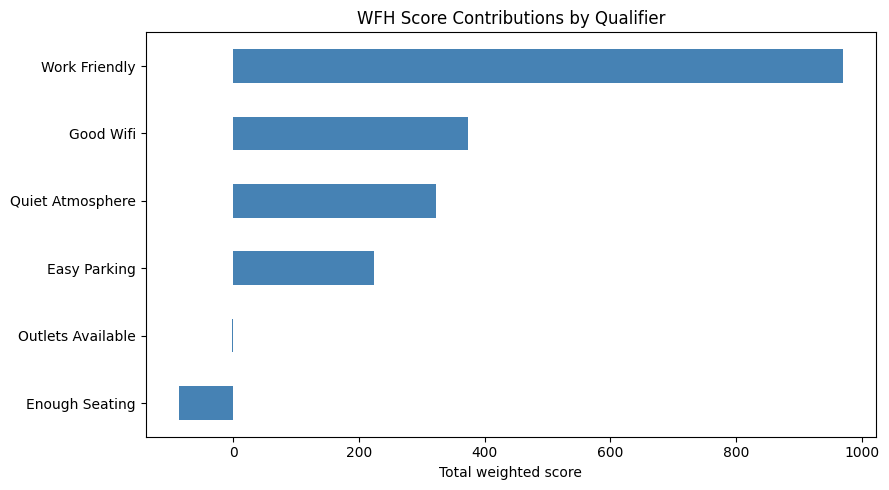

In [103]:
qualifier_columns = [
    f'total_{qualifier}' for qualifier in qualifiers
]

totals = (
    clean_data_3[qualifier_columns]
    .sum()
    .sort_values()
)

totals.index = (
    totals.index
    .str.replace('total_', '', regex=False)
    .str.replace('_', ' ')
    .str.title()
)

totals.plot.barh(figsize=(9, 5), color='steelblue')

plt.xlabel('Total weighted score')
plt.ylabel('')
plt.title('WFH Score Contributions by Qualifier')
plt.tight_layout()
plt.show()

In [104]:
columns_to_add = [
    'total_good_wifi',
    'total_easy_parking',
    'total_quiet_atmosphere',
    'total_enough_seating',
    'total_outlets_available',
    'total_work_friendly',
    'total_wfh_score',
]

final_table = (
    final_table.drop(columns=columns_to_add, errors='ignore')
    .merge(
        clean_data_3[['business_id'] + columns_to_add],
        on='business_id',
        how='left',
        validate='many_to_one',
    )
)

final_table.head()

,business_id,total_reviews,average_wfh_score,wfh_flag,name,address,city,state,postal_code,latitude,...,average_wfh_score_normalized,combined_wfh_score,final_bucket,total_good_wifi,total_easy_parking,total_quiet_atmosphere,total_enough_seating,total_outlets_available,total_work_friendly,total_wfh_score
0,-kY_HDP7IMvGl-kBIZVU4A,330,0.160606,0,Dune Coffee Roasters - Anacapa,528 Anacapa St,Santa Barbara,CA,93101,34.418994,...,0.159643,0.267215,Other,18,18,6,14,-25,22,53
1,-loV4cB2Uh9TCltTRgGzWQ,386,-0.044041,0,Renaud's Patisserie & Bistro,"1324 State St, Ste N, Arlington Plaza",Santa Barbara,CA,93101,34.425368,...,0.069044,0.269998,Other,-2,16,7,-40,0,2,-17
2,0Qs-G8Xs-mz-jmQH5lez5A,23,0.130435,0,Museum Cafe,1130 State St,Santa Barbara,CA,93101,34.423471,...,0.146286,0.2592,Other,0,0,2,-1,0,2,3
3,0RxU5OglQyPVtLKC1LPgsA,511,-0.037182,0,Bree'osh,"1150 Coast Village Rd, Ste E",Santa Barbara,CA,93108,34.421408,...,0.072081,0.328963,Other,2,10,3,-36,0,2,-19
4,0iHHsSqphxrBWWecYEJcuQ,72,0.708333,1,Cajé Coffee - Arlington St,1316 State St,Santa Barbara,CA,93101,34.424853,...,0.402127,0.469847,WFH,-2,-1,10,9,1,34,51


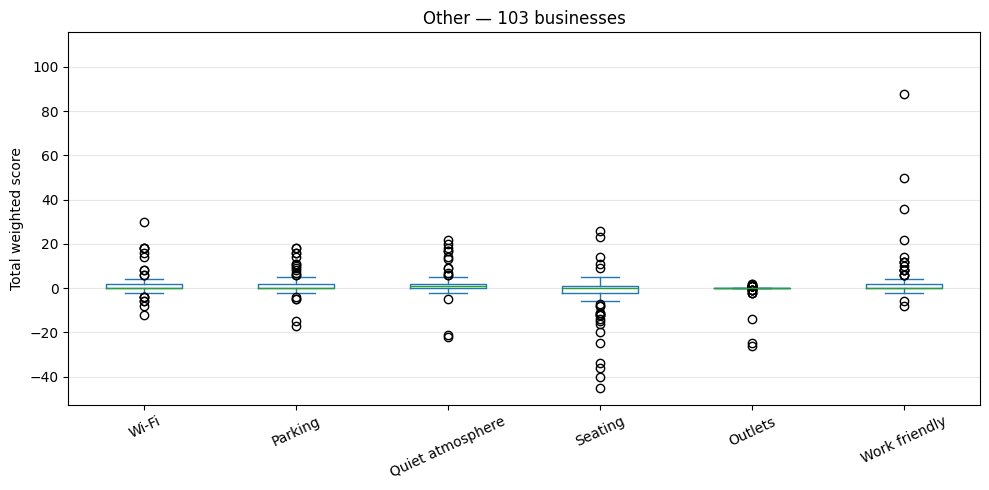

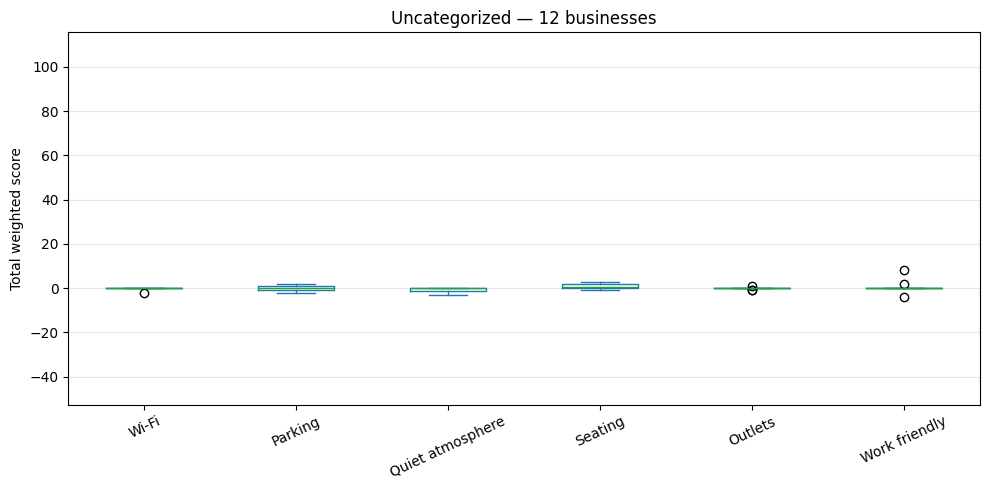

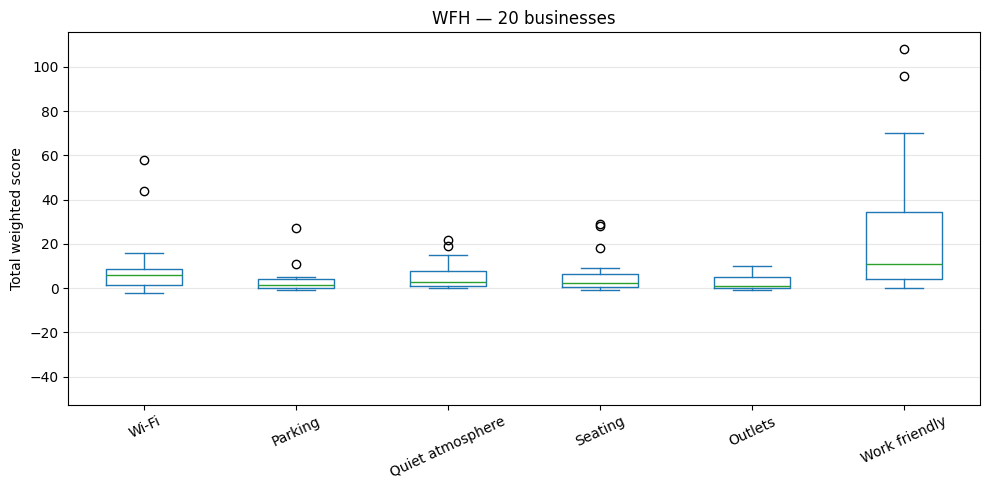

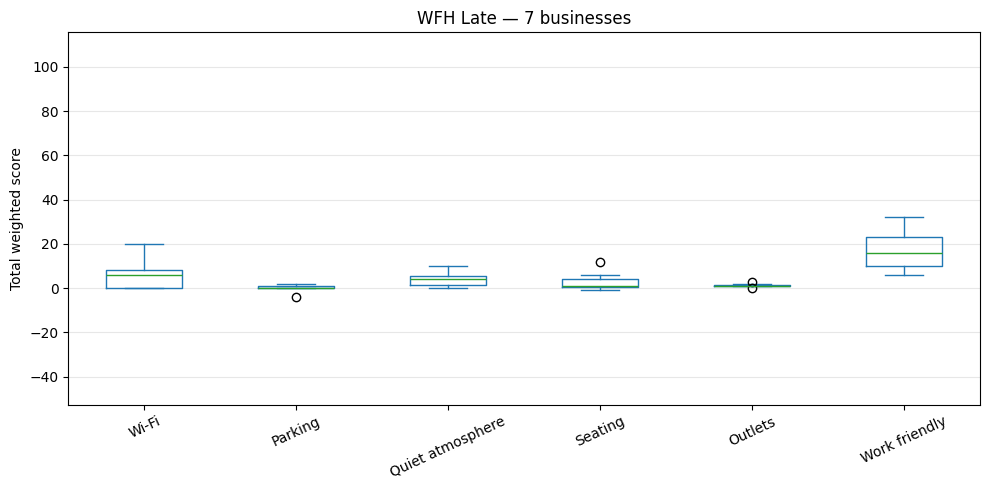

In [105]:
columns = [
    'total_good_wifi',
    'total_easy_parking',
    'total_quiet_atmosphere',
    'total_enough_seating',
    'total_outlets_available',
    'total_work_friendly',
]

labels = [
    'Wi-Fi', 'Parking', 'Quiet atmosphere',
    'Seating', 'Outlets', 'Work friendly',
]

# Use the same scale to make buckets easier to compare.
y_min = final_table[columns].min().min()
y_max = final_table[columns].max().max()
padding = max((y_max - y_min) * 0.05, 1)

for bucket, group in final_table.groupby('final_bucket'):
    ax = group[columns].rename(
        columns=dict(zip(columns, labels))
    ).plot.box(figsize=(10, 5), rot=25)

    ax.set_title(f'{bucket} — {len(group)} businesses')
    ax.set_ylabel('Total weighted score')
    ax.set_ylim(y_min - padding, y_max + padding)
    ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

In [106]:
with pd.option_context('display.max_columns', None):
    display(final_table.head())

,business_id,total_reviews,average_wfh_score,wfh_flag,name,address,city,state,postal_code,latitude,longitude,stars,review_count,is_open,attribute_NoiseLevel,attribute_WiFi,total_late_days,late_close_flag,late_wfh_score,attribute_Ambience_touristy,attribute_Ambience_hipster,attribute_Ambience_romantic,attribute_Ambience_divey,attribute_Ambience_intimate,attribute_Ambience_trendy,attribute_Ambience_upscale,attribute_Ambience_classy,attribute_Ambience_casual,attribute_BusinessParking_garage,attribute_BusinessParking_street,attribute_BusinessParking_validated,attribute_BusinessParking_lot,attribute_BusinessParking_valet,yelp_final_score,yelp_final_score_normalized,average_wfh_score_normalized,combined_wfh_score,final_bucket,total_good_wifi,total_easy_parking,total_quiet_atmosphere,total_enough_seating,total_outlets_available,total_work_friendly,total_wfh_score
0,-kY_HDP7IMvGl-kBIZVU4A,330,0.160606,0,Dune Coffee Roasters - Anacapa,528 Anacapa St,Santa Barbara,CA,93101,34.418994,-119.695068,4.0,320,1,0,1,0,0,0.160606,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0,0,0,1,0,2,0.428571,0.159643,0.267215,Other,18,18,6,14,-25,22,53
1,-loV4cB2Uh9TCltTRgGzWQ,386,-0.044041,0,Renaud's Patisserie & Bistro,"1324 State St, Ste N, Arlington Plaza",Santa Barbara,CA,93101,34.425368,-119.705907,4.0,379,1,1,-1,0,0,-0.044041,0,0,0,0,0,0,0,1,1,0,0,0,1,0,3,0.571429,0.069044,0.269998,Other,-2,16,7,-40,0,2,-17
2,0Qs-G8Xs-mz-jmQH5lez5A,23,0.130435,0,Museum Cafe,1130 State St,Santa Barbara,CA,93101,34.423471,-119.703926,4.5,22,0,0,-1,0,0,0.130435,0,0,0,0,0,0,0,0,1,1,1,0,0,0,2,0.428571,0.146286,0.2592,Other,0,0,2,-1,0,2,3
3,0RxU5OglQyPVtLKC1LPgsA,511,-0.037182,0,Bree'osh,"1150 Coast Village Rd, Ste E",Santa Barbara,CA,93108,34.421408,-119.646473,4.5,497,1,0,1,0,0,-0.037182,0,0,0,0,0,0,0,1,1,0,1,0,0,0,4,0.714286,0.072081,0.328963,Other,2,10,3,-36,0,2,-19
4,0iHHsSqphxrBWWecYEJcuQ,72,0.708333,1,Cajé Coffee - Arlington St,1316 State St,Santa Barbara,CA,93101,34.424853,-119.706088,4.5,72,1,0,1,0,0,0.708333,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,1,1,<NA>,<NA>,0,3,0.571429,0.402127,0.469847,WFH,-2,-1,10,9,1,34,51
